# 01 · Artigo 1 — projeto *grassroots* (Souza, Ventin, Tavares & Costa, 2014)

**A matrix approach for optimization of pipe networks in cooling water systems**,
*Chem. Eng. Comm.* 201:1054-1076, DOI 10.1080/00986445.2013.800484.

Este notebook reproduz, com o pacote `cwnet`, as figuras e tabelas da parte *grassroots*:
Figuras 1-4 e Tabelas I-XI. Os valores publicados estão embutidos nas células de
comparação; as diferenças são comentadas (ver também `docs/reproduction_notes.md`).

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cwnet import load_case, run_design_study
from cwnet.reporting import plots, tables

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
CASES = Path("../cases")

In [2]:
case = load_case(CASES / "paper1_grassroots.yaml")
print(case.name)
print(case.description)

Paper 1 - grassroots design of the cooling water network
20 nodes, 23 edges: 1 pump, 17 pipe sections, 5 heat exchangers in parallel


## Figura 1 — estrutura típica de um sistema de água de resfriamento

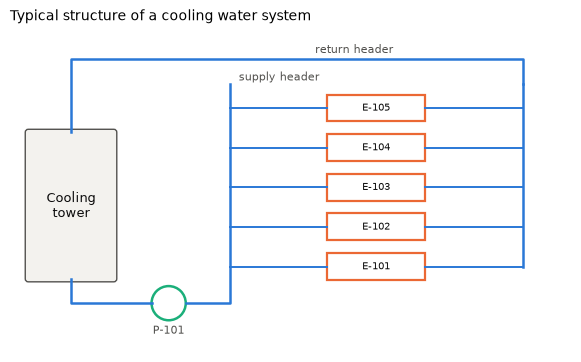

In [3]:
ax = plots.plot_system_schematic(case)

## Figura 2 — digrafo da rede

23 arestas (5 trocadores, 1 bomba, 17 tubulações) e 20 nós. Os nós 1 e 10 são a bacia e o
topo da torre (suprimento e demanda); as demais são nós de conexão.

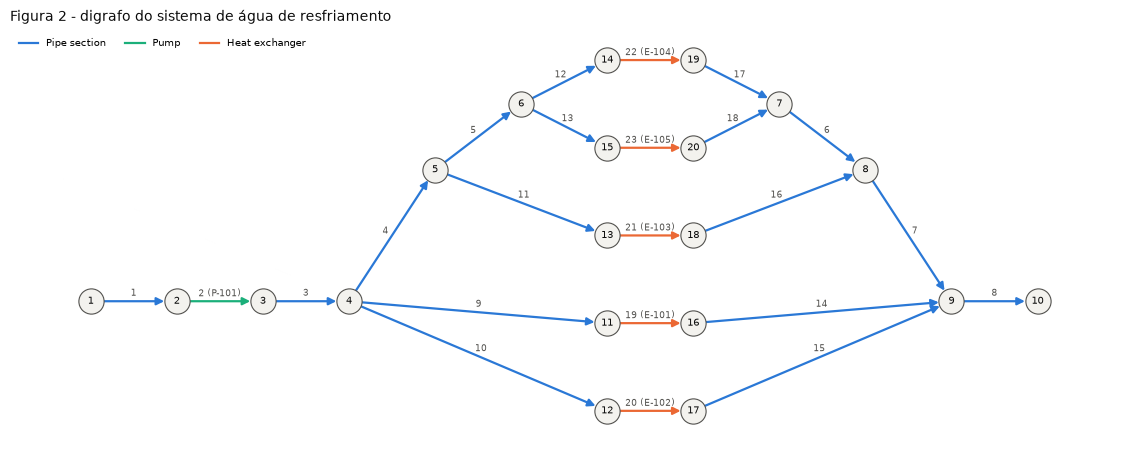

In [4]:
ax = plots.plot_digraph(case, title="Figura 2 - digrafo do sistema de água de resfriamento")

## Figura 3 — descrição *split-pipe* de uma tubulação

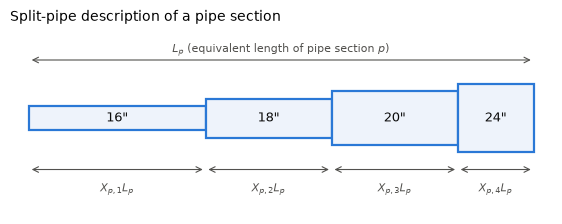

In [5]:
ax = plots.plot_split_pipe(case)

## Figura 4 — algoritmo de solução

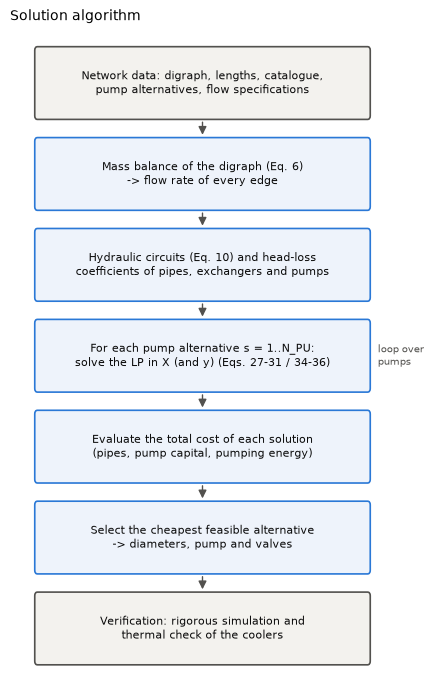

In [6]:
ax = plots.plot_solution_algorithm()

## Tabelas I a VII — dados do problema

In [7]:
print("Tabela I - comprimentos das tubulações"); display(tables.pipe_lengths_table(case))
print("Tabela II - diâmetros comerciais"); display(tables.pipe_catalog_table(case))
print("Tabela III - bombas disponíveis"); display(tables.pump_catalog_table(case))
print("Tabela IV - fatores de custo da bomba"); display(tables.pump_cost_factors_table(case))
print("Tabela V - parâmetros"); display(tables.problem_parameters_table(case))
print("Tabela VI - tarefas térmicas"); display(tables.thermal_tasks_table(case))
print("Tabela VII - dados de projeto dos trocadores"); display(tables.exchanger_design_table(case))

Tabela I - comprimentos das tubulações


,Pipe section,Length (m)
0,1,10.0
1,"9, 10, 11, 13, 14, 15, 16, 18",25.0
2,"4, 5, 6, 7",100.0
3,"12, 17",125.0
4,"3, 8",200.0


Tabela II - diâmetros comerciais


,Nominal diameter (in),Inner diameter (mm),Outer diameter (mm)
0,1/2,15.8,21.3
1,3/4,21.0,26.7
2,1,26.6,33.4
3,1 1/4,35.1,42.2
4,1 1/2,40.9,48.3
5,2,52.5,60.3
6,2 1/2,62.7,73.0
7,3,77.9,88.9
8,3 1/2,90.1,101.6
9,4,102.3,114.3


Tabela III - bombas disponíveis


...

,Parameter,Value,Unit
0,Cooling water density,995.00000,kg/m3
1,Cooling water viscosity,0.00072,Pa.s
2,Cooling water heat capacity,4187.00000,J/(kg K)
3,Cooling water inlet temperature,32.00000,degC
4,Maximum flow velocity,3.70000,m/s
5,Pump efficiency (eta),0.60000,-
6,Number of operating hours (Nop),8760.00000,hours/year
7,Energy cost (pc),0.10000,USD/kWh
8,Interest rate (i),0.12000,-
9,Project horizon (ny),20.00000,years


Tabela VI - tarefas térmicas


,Heat exchanger,Flow rate (kg/s) hot / cold,Inlet temperature (degC) hot / cold,Outlet temperature (degC) hot / cold,Heat capacity (J/kg K) hot / cold
0,E-101,12 / 11.8,80 / 32,65 / 40,2200 / 4187
1,E-102,12 / 28.7,120 / 32,80 / 40,2000 / 4187
2,E-103,10.5 / 35.6,80 / 32,40 / 40,2840 / 4187
3,E-104,8.5 / 15.6,69 / 32,41 / 40,2200 / 4187
4,E-105,1.7 / 3.1,69 / 32,41 / 40,2200 / 4187


Tabela VII - dados de projeto dos trocadores


,Heat exchanger,Area (m2),Film coefficient (W/m2 K) tube / shell,Total fouling factor (m2 K/W),Design cooling water flow (kg/s),Design cooling water head loss (m)
0,E-101,27.3,10615 / 658,0.00051,11.8,5.53
1,E-102,76.7,10651 / 266,0.00076,28.7,6.35
2,E-103,133.6,8864 / 923,0.00048,35.6,4.82
3,E-104,109.5,6187 / 450,0.00049,15.6,2.97
4,E-105,47.4,3645 / 216,0.00098,3.1,1.20


## Matrizes da formulação (Eqs. 1-3, 7-10)

A matriz de incidência `K`, os vetores de classificação dos nós e a matriz de circuitos
hidráulicos `Λ` (Eq. 10) são construídos automaticamente a partir do digrafo.

In [8]:
study = run_design_study(case, traditional_methods=["edgar_himmelblau", "towler"])
topo = study.topology
print("K:", topo.incidence.shape, "| nós de suprimento/demanda:", topo.supply_node, topo.demand_node)
print("circuitos hidráulicos (Λ):")
display(tables.circuit_table(study))

K: (20, 23) | nós de suprimento/demanda: 1 10
circuitos hidráulicos (Λ):


,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
Circuit 1 (E-101),1,1,1,0,0,0,0,1,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0
Circuit 2 (E-102),1,1,1,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0
Circuit 3 (E-103),1,1,1,1,0,0,1,1,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0
Circuit 4 (E-104),1,1,1,1,1,1,1,1,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0
Circuit 5 (E-105),1,1,1,1,1,1,1,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1


## Tabela VIII — vazões mássicas da rede (balanço de massa, Eq. 6)

In [9]:
display(tables.mass_flow_table(study))

,Edge,Mass flow rate (kg/s)
0,"1, 2, 3, 8",94.8
1,"4, 7",54.3
2,"11, 16, 21",35.6
3,"10, 15, 20",28.7
4,"5, 6",18.7
5,"12, 17, 22",15.6
6,"9, 14, 19",11.8
7,"13, 18, 23",3.1


## Tabela IX — projeto tradicional (Edgar & Himmelblau) e projeto otimizado (LP)

O LP para a bomba 1 é o mais barato. O ótimo do LP é **degenerado**: tubulações em série
com a mesma vazão (por exemplo 1, 3 e 8 no coletor principal) podem trocar entre si os
trechos de diâmetro sem alterar o custo; o vértice publicado e o encontrado aqui diferem
apenas nessa escolha. A célula seguinte verifica que, em cada grupo de tubulações em série,
o comprimento total de cada diâmetro é o mesmo que o publicado.

In [10]:
PUBLISHED_TABLE_IX = {   # edge: (traditional, optimization diameters, length fractions)
    1: ("12", "10", "1.000"), 3: ("12", "12", "1.000"), 4: ("8", "8", "1.000"),
    5: ("5", "6", "1.000"), 6: ("5", "6", "1.000"), 7: ("8", "8/10", "0.399/0.601"),
    8: ("12", "10/12", "0.810/0.190"), 9: ("4", "3 1/2", "1.000"), 10: ("6", "6", "1.000"),
    11: ("8", "8", "1.000"), 12: ("5", "6", "1.000"), 13: ("2 1/2", "1 1/2/2", "0.225/0.775"),
    14: ("4", "3 1/2/4", "0.203/0.797"), 15: ("6", "6", "1.000"), 16: ("8", "6/8", "0.353/0.647"),
    17: ("5", "6", "1.000"), 18: ("2 1/2", "2", "1.000"),
}
PUBLISHED_TABLE_X = {  # tag: (design flow, design Tho, simulated flow, simulated Tho)
    "E-101": (11.8, 65.0, 13.8, 63.2), "E-102": (28.7, 80.0, 32.2, 78.2), "E-103": (35.6, 40.0, 39.8, 39.1),
    "E-104": (15.6, 41.0, 12.7, 41.7), "E-105": (3.1, 41.0, 4.2, 38.6),
}
PUBLISHED_TABLE_XI = {  # (total, operating, pump, pipe) USD/y
    "Traditional (edgar_himmelblau)": (42815, 23184, 3209, 16422),
    "Proposed / Curve 1": (39811, 20183, 3045, 16583), "Proposed / Curve 2": (41768, 24220, 3209, 14339),
    "Proposed / Curve 3": (43939, 26911, 3312, 13716), "Proposed / Curve 4": (46292, 29602, 3409, 13281),
}

design_tbl = tables.design_comparison_table(study, traditional="edgar_himmelblau")
design_tbl["Published traditional"] = [PUBLISHED_TABLE_IX[e][0] for e in design_tbl["Edge"]]
design_tbl["Published optimization"] = [PUBLISHED_TABLE_IX[e][1] for e in design_tbl["Edge"]]
design_tbl["Published fraction"] = [PUBLISHED_TABLE_IX[e][2] for e in design_tbl["Edge"]]
display(design_tbl)

,Edge,Traditional diameter (in),Optimization diameter (in),Optimization length fraction,Published traditional,Published optimization,Published fraction
0,1,12,12,1.000,12,10,1.000
1,3,12,12,1.000,12,12,1.000
2,4,8,8,1.000,8,8,1.000
3,5,5,6,1.000,5,6,1.000
4,6,5,6,1.000,5,6,1.000
5,7,8,8/10,0.399/0.601,8,8/10,0.399/0.601
6,8,12,10/12,0.860/0.140,12,10/12,0.810/0.190
7,9,4,3 1/2/4,0.203/0.797,4,3 1/2,1.000
8,10,6,6,1.000,6,6,1.000
9,11,8,6/8,0.353/0.647,8,8,1.000


In [11]:
def length_by_diameter(design, edges):
    out = {}
    for e in edges:
        for n, f in design.pipes[e].subsections:
            dn = case.pipe_catalog.sizes[n].label
            out[dn] = out.get(dn, 0.0) + f * case.pipe(e).length
    return {k: round(v, 2) for k, v in sorted(out.items())}

def published_length_by_diameter(edges):
    out = {}
    for e in edges:
        labels = PUBLISHED_TABLE_IX[e][1].split("/") if "/" not in PUBLISHED_TABLE_IX[e][1].replace("1 1/2", "x").replace("3 1/2", "y") else None
        # labels with fractions such as "1 1/2/2" need care: use the catalogue labels
        cat = [s.label for s in case.pipe_catalog.sizes]
        text = PUBLISHED_TABLE_IX[e][1]
        parts = []
        for lab in sorted(cat, key=len, reverse=True):
            if text.startswith(lab):
                parts.append(lab); text = text[len(lab):].lstrip("/")
                if text:
                    parts.append(text)
                break
        fr = [float(x) for x in PUBLISHED_TABLE_IX[e][2].split("/")]
        for lab, f in zip(parts, fr):
            out[lab] = out.get(lab, 0.0) + f * case.pipe(e).length
    return {k: round(v, 2) for k, v in sorted(out.items())}

best = study.best.design
groups = {"coletor principal (1, 3, 8)": (1, 3, 8), "4 e 7": (4, 7), "9 e 14": (9, 14),
          "11 e 16": (11, 16), "13 e 18": (13, 18), "10 e 15": (10, 15), "5, 6": (5, 6), "12, 17": (12, 17)}
rows = []
for name, edges in groups.items():
    rows.append({"grupo em série": name, "comprimento por diâmetro (cwnet)": length_by_diameter(best, edges),
                 "comprimento por diâmetro (publicado)": published_length_by_diameter(edges)})
display(pd.DataFrame(rows))
print("custo de tubulação (LP, bomba 1): %.0f USD" % study.best.costs.pipe_capital)

,grupo em série,comprimento por diâmetro (cwnet),comprimento por diâmetro (publicado)
0,"coletor principal (1, 3, 8)","{'10': 172.03, '12': 237.97}","{'10': 172.0, '12': 238.0}"
1,4 e 7,"{'10': 60.06, '8': 139.94}","{'10': 60.1, '8': 139.9}"
2,9 e 14,"{'3 1/2': 30.08, '4': 19.92}","{'3 1/2': 30.07, '4': 19.93}"
3,11 e 16,"{'6': 8.82, '8': 41.18}","{'6': 8.82, '8': 41.17}"
4,13 e 18,"{'1 1/2': 5.63, '2': 44.37}","{'1 1/2': 5.62, '2': 44.38}"
5,10 e 15,{'6': 50.0},{'6': 50.0}
6,"5, 6",{'6': 200.0},{'6': 200.0}
7,"12, 17",{'6': 250.0},{'6': 250.0}


custo de tubulação (LP, bomba 1): 16581 USD


## Tabela X — comportamento da rede com o projeto tradicional

A rede tradicional é simulada rigorosamente (balanços de massa e energia mecânica com a
curva da bomba 2) e o desempenho térmico dos trocadores é avaliado pelo método ε-NTU
(rotina `heatcheck` do código original). As **vazões simuladas** coincidem com as
publicadas (102.7 kg/s no total; E-104 recebe só 81 % da vazão de projeto). As
**temperaturas** de saída diferem em até ~1 °C das publicadas porque o artigo usou o
simulador termo-hidráulico de Tavares et al. (2010), mais detalhado do que o modelo ε-NTU
disponível aqui.

In [12]:
trad = study.traditional["edgar_himmelblau"]
tab_x = tables.network_behaviour_table(trad)
pub = pd.DataFrame([{"Heat exchanger": k, "Published simulated flow (kg/s)": v[2], "Published simulated hot outlet (degC)": v[3]}
                    for k, v in PUBLISHED_TABLE_X.items()])
display(tab_x.merge(pub, on="Heat exchanger", how="left"))
print("bomba selecionada pelo método tradicional:", trad.design.pump_curve,
      "| head mínimo requerido: %.2f m (artigo: 17.8 m)" % trad.design.required_pump_head)

,Heat exchanger,Design flow (kg/s),Simulated flow (kg/s),Design hot outlet (degC),Simulated hot outlet (degC),Simulated cold outlet (degC),Published simulated flow (kg/s),Published simulated hot outlet (degC)
0,E-101,11.8,13.84,65.0,63.9,39.4,13.8,63.2
1,E-102,28.7,32.26,80.0,79.0,39.3,32.2,78.2
2,E-103,35.6,39.81,40.0,39.6,39.2,39.8,39.1
3,E-104,15.6,12.57,41.0,42.0,41.6,12.7,41.7
4,E-105,3.1,4.26,41.0,39.5,38.2,4.2,38.6
5,Total,94.8,102.74,NaN,NaN,NaN,NaN,NaN


bomba selecionada pelo método tradicional: Curve 2 | head mínimo requerido: 17.66 m (artigo: 17.8 m)


## Tabela XI — comparação econômica

Custos em USD/ano. Nota: na tabela publicada (e no código Scilab original) a coluna
*pipe cost* é o **investimento** em tubos (não anualizado), enquanto o custo da bomba é
anualizado; `objective_basis: published` reproduz essa convenção. A diferença de ~2 USD vem
do fator de conversão arredondado (3.281 ft/m) usado no código original.

In [13]:
costs = tables.cost_comparison_table(study)
costs = costs[costs["Methodology / case"] != "Traditional (towler)"].copy()
for i, col in enumerate(["Total cost (USD/y)", "Operational cost (USD/y)", "Pump cost (USD/y)", "Pipe cost (USD)"]):
    costs[f"Published {col}"] = [PUBLISHED_TABLE_XI[m][i] for m in costs["Methodology / case"]]
    costs[f"Δ {col}"] = costs[col] - costs[f"Published {col}"]
display(costs)
best_total = study.best.costs.total; trad_total = trad.costs.total
print("redução de custo do projeto proposto (bomba 1) vs tradicional: %.1f %% (artigo: 7.0 %%)" % (100 * (1 - best_total / trad_total)))

,Methodology / case,Pump,Total cost (USD/y),Operational cost (USD/y),Pump cost (USD/y),Pipe cost (USD),Feasible,Published Total cost (USD/y),Δ Total cost (USD/y),Published Operational cost (USD/y),Δ Operational cost (USD/y),Published Pump cost (USD/y),Δ Pump cost (USD/y),Published Pipe cost (USD),Δ Pipe cost (USD)
0,Traditional (edgar_himmelblau),Curve 2,42813,23184,3209,16420,True,42815,-2,23184,0,3209,0,16422,-2
2,Proposed / Curve 1,Curve 1,39808,20183,3045,16581,True,39811,-3,20183,0,3045,0,16583,-2
3,Proposed / Curve 2,Curve 2,41766,24220,3209,14337,True,41768,-2,24220,0,3209,0,14339,-2
4,Proposed / Curve 3,Curve 3,43936,26911,3312,13714,True,43939,-3,26911,0,3312,0,13716,-2
5,Proposed / Curve 4,Curve 4,46291,29602,3409,13280,True,46292,-1,29602,0,3409,0,13281,-1


redução de custo do projeto proposto (bomba 1) vs tradicional: 7.0 % (artigo: 7.0 %)


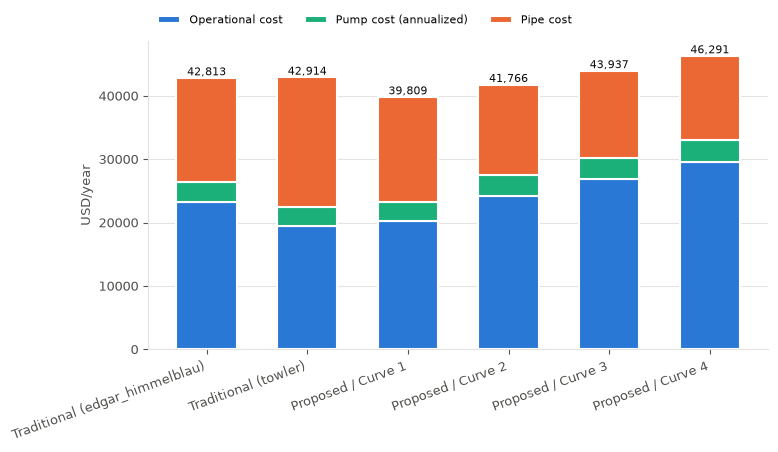

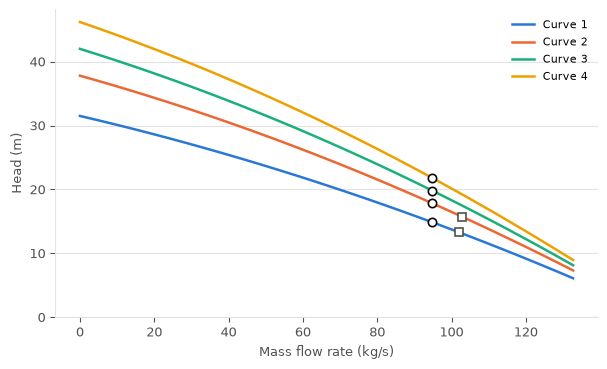

In [14]:
ax = plots.plot_cost_comparison(study)
ax2 = plots.plot_pump_curves(study)

## Verificação do projeto ótimo

A simulação rigorosa da rede otimizada devolve exatamente as vazões especificadas (rede
hidraulicamente balanceada, sem válvulas), como afirmado no artigo.

In [15]:
display(tables.pipe_results_table(study.best, case))
display(tables.network_behaviour_table(study.best))
print("balanceada:", study.best.hydraulically_balanced, "| válvulas:", study.best.design.valves)

,Edge,Length (m),Diameter (in),Length fraction,Mass flow (kg/s),Velocity (m/s),Head loss (m),Upstream pressure (bar g),Downstream pressure (bar g)
0,1,10.0,12,1.000,94.8,1.32,0.044,-0.000,-0.004
1,3,200.0,12,1.000,94.8,1.32,0.870,1.447,1.362
2,4,100.0,8,1.000,54.3,1.69,1.138,1.362,1.251
3,5,100.0,6,1.000,18.7,1.01,0.593,1.251,1.193
4,6,100.0,6,1.000,18.7,1.01,0.593,0.800,0.742
5,7,100.0,8/10,0.399/0.601,54.3,1.69 / 1.07,0.673,0.742,0.677
6,8,200.0,10/12,0.860/0.140,94.8,1.87 / 1.32,1.932,0.677,0.000
7,9,25.0,3 1/2/4,0.203/0.797,11.8,1.86 / 1.44,0.571,1.362,1.306
8,10,25.0,6,1.000,28.7,1.55,0.334,1.362,1.329
9,11,25.0,6/8,0.353/0.647,35.6,1.92 / 1.11,0.261,1.251,1.225


,Heat exchanger,Design flow (kg/s),Simulated flow (kg/s),Design hot outlet (degC),Simulated hot outlet (degC),Simulated cold outlet (degC)
0,E-101,11.8,11.8,65.0,64.1,40.5
1,E-102,28.7,28.7,80.0,79.3,40.1
2,E-103,35.6,35.6,40.0,40.1,40.0
3,E-104,15.6,15.6,41.0,41.1,40.0
4,E-105,3.1,3.1,41.0,40.6,40.2
5,Total,94.8,94.8,NaN,NaN,NaN


balanceada: True | válvulas: {'design': {'E-101': 0.0, 'E-102': 0.0, 'E-103': 0.0, 'E-104': 0.0, 'E-105': 0.0}}


## Nota: ranking com custos totalmente anualizados

Aplicando o fator de anualização também ao investimento em tubos (Eqs. 15-18 do artigo),
o ranking das bombas neste caso não muda (bomba 1 continua a melhor):

In [16]:
display(tables.cost_comparison_table(study, basis="annualized"))

,Methodology / case,Pump,Total cost (USD/y),Operational cost (USD/y),Pump cost (USD/y),Pipe cost (USD),Feasible
0,Traditional (edgar_himmelblau),Curve 2,28592,23184,3209,16420,True
1,Traditional (towler),Curve 1,25203,19420,3045,20449,True
2,Proposed / Curve 1,Curve 1,25447,20183,3045,16581,True
3,Proposed / Curve 2,Curve 2,29348,24220,3209,14337,True
4,Proposed / Curve 3,Curve 3,32058,26911,3312,13714,True
5,Proposed / Curve 4,Curve 4,34789,29602,3409,13280,True
